# 01 – EDA: Kaggle Playground S6E11 – Predicting Credit Card Fraud
**Người 1 (Data & EDA)** · Metric: ROC AUC · Target: `is_fraud`

Notebook này trả lời 5 câu hỏi: (1) dữ liệu có sạch không, (2) bài toán mất cân bằng đến đâu, (3) cột nào có tín hiệu, (4) train và test có cùng phân phối không, (5) nên chọn cách chia fold nào.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

# Tự tìm thư mục dữ liệu (chạy từ gốc dự án hoặc từ notebooks/)
for d in ["data/raw", "../data/raw", "/kaggle/input/playground-series-s6e11"]:
    if os.path.exists(os.path.join(d, "train.csv")):
        DATA_DIR = d; break
else:
    raise FileNotFoundError("Không thấy train.csv – đặt file vào data/raw/")

train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test  = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
TARGET, ID = "is_fraud", "id"

CAT  = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
BOOL = [c for c in train.columns if train[c].dtype == bool]
NUM  = [c for c in train.columns if c not in CAT + BOOL + [ID, TARGET]]
print("Thư mục dữ liệu:", DATA_DIR)
print(f"train {train.shape} | test {test.shape}")
print(f"{len(CAT)} cột chữ, {len(BOOL)} cột bool, {len(NUM)} cột số")
train.head()

Thư mục dữ liệu: ../data/raw
train (699960, 26) | test (299984, 25)
5 cột chữ, 6 cột bool, 13 cột số


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


## 1. Chất lượng dữ liệu

In [2]:
quality = pd.DataFrame({
    "missing_train": train.isna().sum(),
    "missing_test":  test.reindex(columns=train.columns).isna().sum(),
    "n_unique":      train.nunique(),
    "dtype":         train.dtypes.astype(str)})
print("Tổng missing train/test:", int(quality.missing_train.sum()), "/", int(quality.missing_test.drop(TARGET).sum()))
print("ID trùng trong train:", train[ID].duplicated().sum(), "| trùng trong test:", test[ID].duplicated().sum())
print("Dòng trùng hoàn toàn (bỏ id):", train.drop(columns=ID).duplicated().sum())
print("Khoảng id: train", train[ID].min(), "-", train[ID].max(), "| test", test[ID].min(), "-", test[ID].max())
print("Bộ giá trị cột chữ giống nhau giữa train và test:", all(set(train[c]) == set(test[c]) for c in CAT))
quality

Tổng missing train/test: 0 / 0
ID trùng trong train: 0 | trùng trong test: 0


Dòng trùng hoàn toàn (bỏ id): 0
Khoảng id: train 0 - 699959 | test 699960 - 999943


Bộ giá trị cột chữ giống nhau giữa train và test: True


,missing_train,missing_test,n_unique,dtype
id,0,0,699960,int64
amount_usd,0,0,13387,float64
hours_since_last_txn,0,0,3633,float64
txn_count_last_24h,0,0,12,int64
distance_from_home_km,0,0,4365,float64
card_age_months,0,0,49,int64
customer_age,0,0,64,int64
account_balance_usd,0,0,43317,float64
cvv_retry_count,0,0,4,int64
velocity_score,0,0,666,float64


## 2. Mức độ mất cân bằng của target

Fraud: 11,689 / 699,960 = 1.67%  (tỉ lệ 1 fraud : 59 bình thường)
Model đoán toàn 'không gian lận' đạt accuracy 98.33% nhưng AUC = 0.5 -> vì vậy dùng AUC.


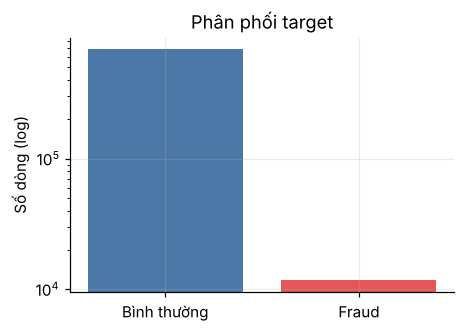

In [3]:
vc = train[TARGET].value_counts()
rate = train[TARGET].mean()
print(f"Fraud: {vc.get(1,0):,} / {len(train):,} = {rate:.2%}  (tỉ lệ 1 fraud : {vc.get(0,0)/max(vc.get(1,1),1):.0f} bình thường)")
print(f"Model đoán toàn 'không gian lận' đạt accuracy {1-rate:.2%} nhưng AUC = 0.5 -> vì vậy dùng AUC.")
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(["Bình thường", "Fraud"], [vc.get(0,0), vc.get(1,0)], color=["#4c78a8", "#e45756"])
ax.set_yscale("log"); ax.set_ylabel("Số dòng (log)"); ax.set_title("Phân phối target"); plt.show()

## 3. Cột chữ: tỉ lệ fraud theo từng giá trị

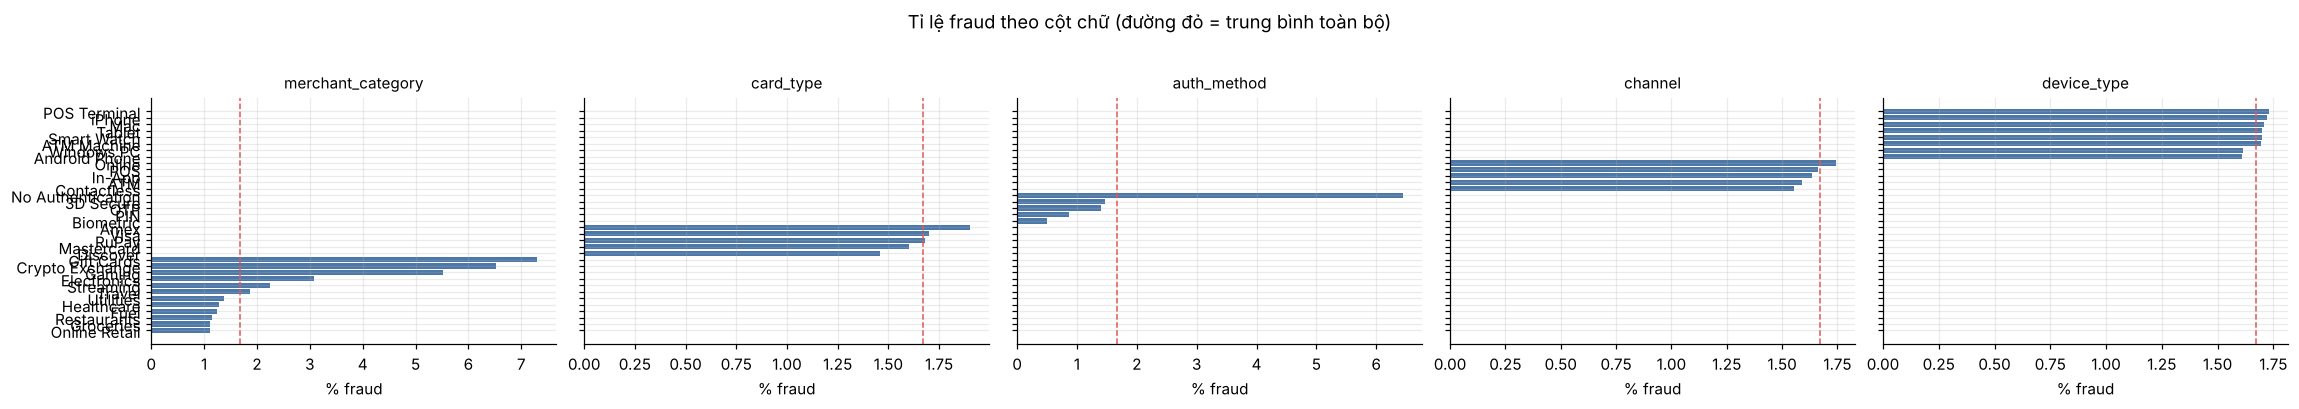

In [4]:
fig, axes = plt.subplots(1, len(CAT), figsize=(4.2*len(CAT), 3.6), sharey=True)
for ax, c in zip(axes, CAT):
    g = train.groupby(c)[TARGET].agg(["mean", "size"]).sort_values("mean")
    ax.barh(g.index.astype(str), g["mean"]*100, color="#4c78a8")
    ax.axvline(rate*100, color="#e45756", ls="--", lw=1)
    ax.set_title(c, fontsize=10); ax.set_xlabel("% fraud")
axes[0].set_ylabel(""); fig.suptitle("Tỉ lệ fraud theo cột chữ (đường đỏ = trung bình toàn bộ)", y=1.02); plt.tight_layout(); plt.show()

## 4. Cột bool: tỉ lệ fraud khi True / False

In [5]:
rows = []
for c in BOOL:
    g = train.groupby(c)[TARGET].agg(["mean", "size"])
    rows.append({"cột": c, "fraud% khi False": g.loc[False,"mean"]*100, "fraud% khi True": g.loc[True,"mean"]*100,
                 "số dòng True": int(g.loc[True,"size"]), "% dòng True": g.loc[True,"size"]/len(train)*100})
bool_tbl = pd.DataFrame(rows).set_index("cột").round(2)
bool_tbl.sort_values("fraud% khi True", ascending=False)

,fraud% khi False,fraud% khi True,số dòng True,% dòng True
cột,,,,
ip_country_mismatch,1.43,16.50,11312,1.62
is_ai_generated_scam_attempt,1.63,15.22,2299,0.33
billing_shipping_mismatch,1.52,12.99,9054,1.29
is_foreign_transaction,1.48,12.57,12098,1.73
used_vpn,1.50,6.55,23665,3.38
is_new_merchant,1.12,4.73,106720,15.25


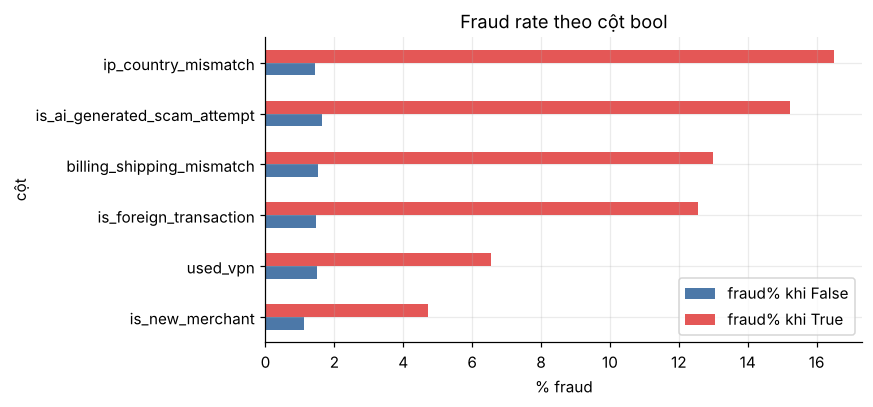

In [6]:
ax = bool_tbl.sort_values("fraud% khi True")[["fraud% khi False", "fraud% khi True"]].plot.barh(figsize=(7, 3.6), color=["#4c78a8", "#e45756"])
ax.set_xlabel("% fraud"); ax.set_title("Fraud rate theo cột bool"); plt.show()

## 5. Cột số

### 5.1 Cột số rời rạc (ít giá trị): fraud rate theo từng giá trị

Cột số rời rạc: ['txn_count_last_24h', 'cvv_retry_count', 'day_of_week', 'prior_disputes']


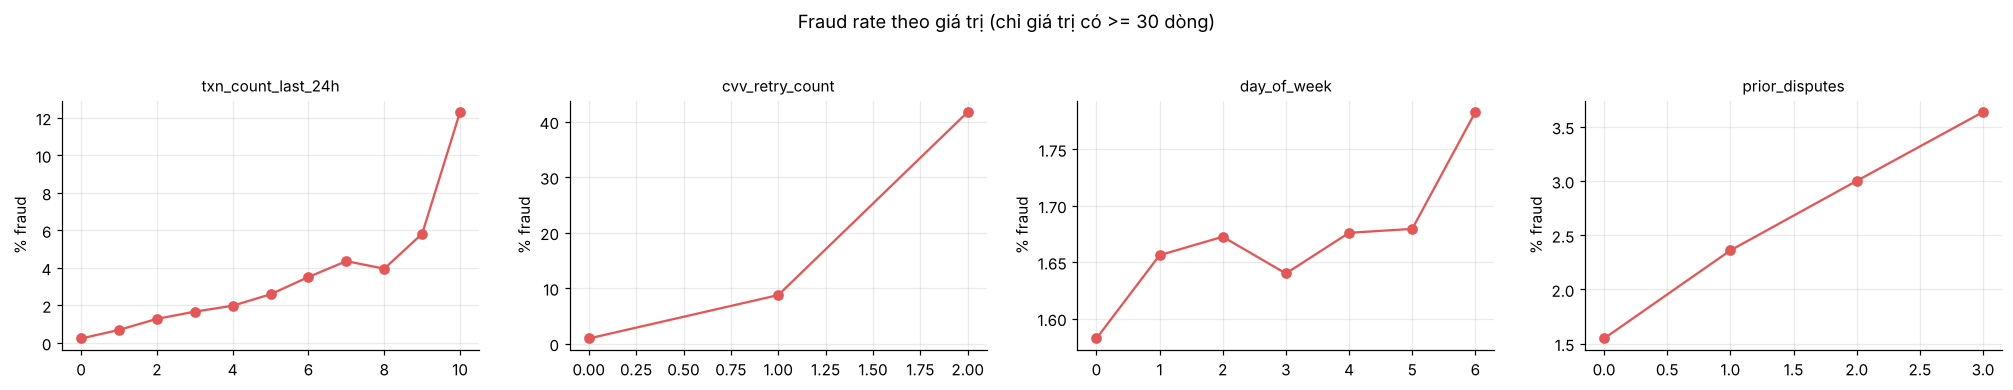

In [7]:
DISC = [c for c in NUM if train[c].nunique() <= 15]
print("Cột số rời rạc:", DISC)
fig, axes = plt.subplots(1, len(DISC), figsize=(4.6*len(DISC), 3.4))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, DISC):
    g = train.groupby(c)[TARGET].agg(["mean", "size"])
    g = g[g["size"] >= 30]            # bỏ giá trị quá hiếm cho khỏi nhiễu
    ax.plot(g.index, g["mean"]*100, marker="o", color="#e45756"); ax.set_title(c, fontsize=10); ax.set_ylabel("% fraud")
fig.suptitle("Fraud rate theo giá trị (chỉ giá trị có >= 30 dòng)", y=1.03); plt.tight_layout(); plt.show()

### 5.2 Cột số liên tục: fraud rate theo thập phân vị (decile)

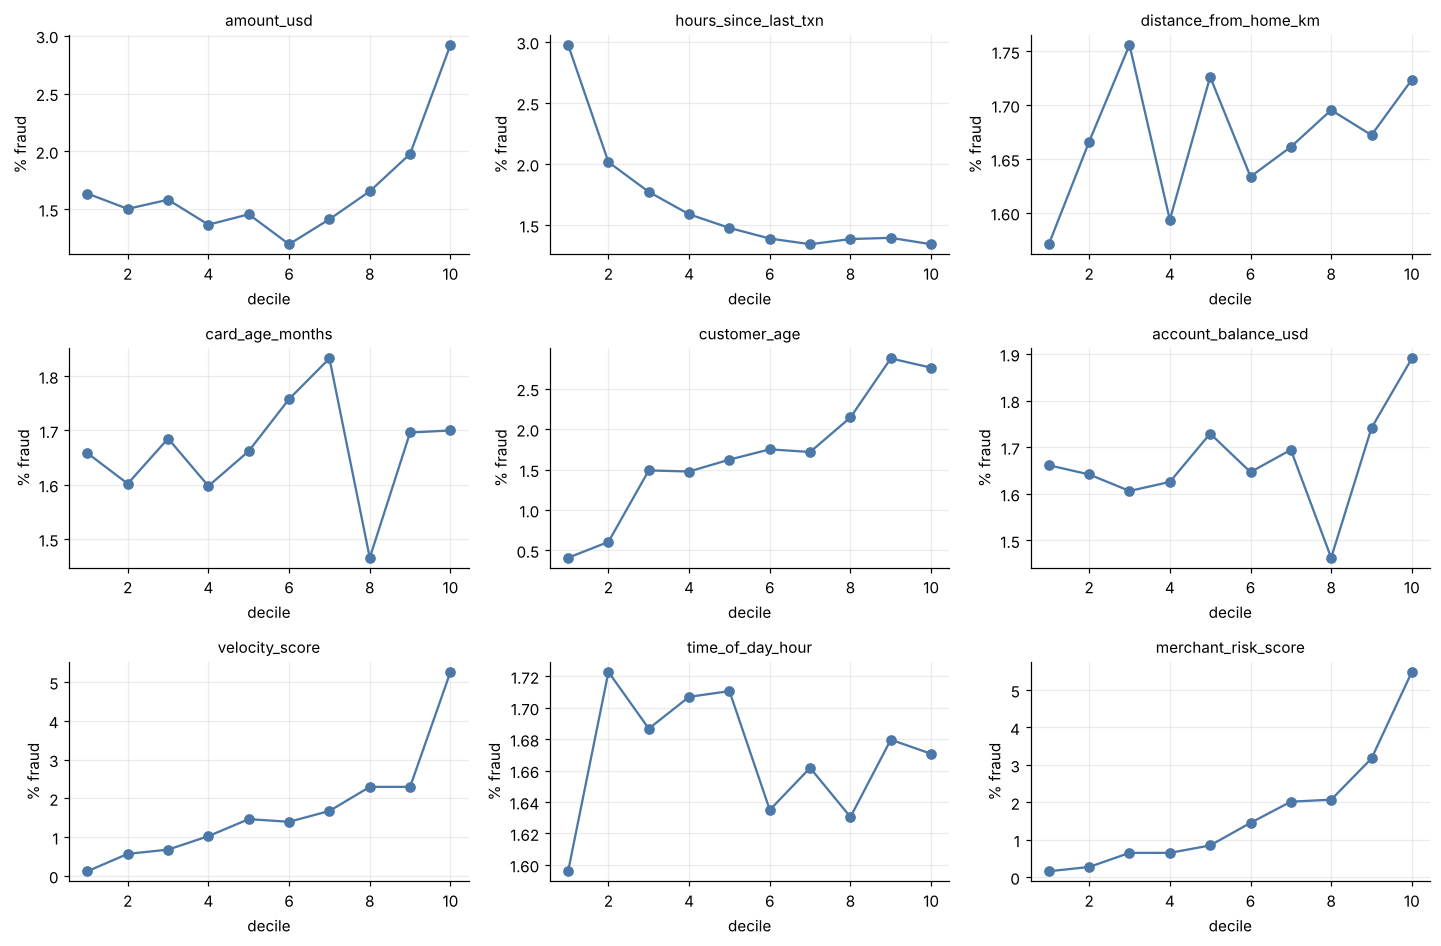

In [8]:
CONT = [c for c in NUM if c not in DISC]
n = len(CONT); cols = 3; rws = int(np.ceil(n/cols))
fig, axes = plt.subplots(rws, cols, figsize=(4.4*cols, 2.9*rws))
for ax, c in zip(axes.ravel(), CONT):
    q = pd.qcut(train[c], 10, duplicates="drop")
    g = train.groupby(q, observed=True)[TARGET].mean()*100
    ax.plot(range(1, len(g)+1), g.values, marker="o", color="#4c78a8"); ax.set_title(c, fontsize=10); ax.set_xlabel("decile"); ax.set_ylabel("% fraud")
for ax in axes.ravel()[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

### 5.3 Xếp hạng tín hiệu: AUC đơn biến của từng cột số

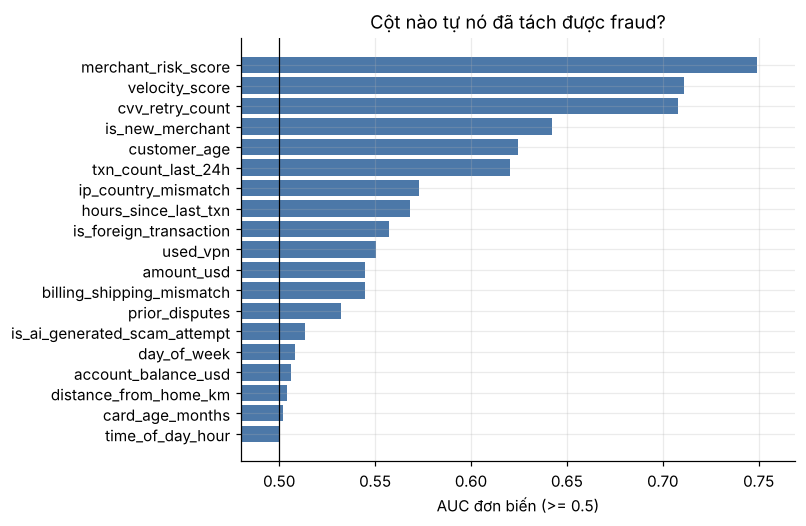

In [9]:
from sklearn.metrics import roc_auc_score
auc1 = {c: roc_auc_score(train[TARGET], train[c]) for c in NUM + BOOL}
s = pd.Series(auc1)
s = (s - 0.5).abs().sort_values().add(0.5)     # đưa về >= 0.5 (hướng nào cũng tính là có tín hiệu)
fig, ax = plt.subplots(figsize=(6.5, 5)); ax.barh(s.index, s.values, color="#4c78a8"); ax.axvline(.5, color="k", lw=.8)
ax.set_xlim(.48, max(s.values)+.02); ax.set_xlabel("AUC đơn biến (>= 0.5)"); ax.set_title("Cột nào tự nó đã tách được fraud?"); plt.show()

## 6. Train và test có cùng phân phối không?

In [10]:
shift = pd.DataFrame({"lệch trung bình (đơn vị std)": [(test[c].mean()-train[c].mean())/train[c].std() for c in NUM]}, index=NUM)
print("Độ lệch trung bình train->test lớn nhất:", shift.abs().max().round(4).item(), "std (nhỏ hơn ~0.02 là gần như không lệch)")
shift.round(4).T

Độ lệch trung bình train->test lớn nhất: 0.0052 std (nhỏ hơn ~0.02 là gần như không lệch)


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes
lệch trung bình (đơn vị std),0.0001,0.001,-0.0002,0.0013,-0.004,-0.0003,0.0019,-0.0004,0.0008,-0.0022,-0.0052,-0.0,0.003


In [11]:
# Adversarial validation: huấn luyện mô hình phân biệt train với test. AUC ~ 0.5 => cùng phân phối.
import lightgbm as lgb
from sklearn.model_selection import cross_val_predict, StratifiedKFold
a = pd.concat([train.drop(columns=[ID, TARGET]).sample(60000, random_state=0).assign(is_test=0),
               test.drop(columns=[ID]).sample(60000, random_state=0).assign(is_test=1)], ignore_index=True)
for c in CAT: a[c] = a[c].astype("category")
for c in BOOL: a[c] = a[c].astype(int)
ya = a.pop("is_test")
p = cross_val_predict(lgb.LGBMClassifier(n_estimators=200, learning_rate=.05, verbose=-1), a, ya,
                      cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]
adv_auc = roc_auc_score(ya, p)
print(f"Adversarial AUC = {adv_auc:.4f}")
print("=> Train/test CÙNG phân phối (không có covariate shift đáng kể)." if adv_auc < 0.52 else "=> CÓ dấu hiệu lệch phân phối, cần xem lại cột nào gây ra.")

Adversarial AUC = 0.4985
=> Train/test CÙNG phân phối (không có covariate shift đáng kể).


## 7. Có cần chia fold theo nhóm hoặc thời gian không?

In [12]:
id_like = [c for c in train.columns if c not in (ID, TARGET) and train[c].nunique() > 0.5*len(train) and train[c].dtype == object]
print("Cột giống mã khách hàng/thẻ (nhiều giá trị duy nhất, dạng chữ):", id_like or "KHÔNG CÓ")
print("Cột thời gian:", [c for c in train.columns if "time" in c or "day" in c or "date" in c])
print("=> Không có cột nhóm (khách hàng/thẻ) và không có mốc thời gian liên tục (chỉ có giờ trong ngày và thứ), nên StratifiedKFold(5, shuffle=True, random_state=42) là phù hợp.")

Cột giống mã khách hàng/thẻ (nhiều giá trị duy nhất, dạng chữ): KHÔNG CÓ
Cột thời gian: ['time_of_day_hour', 'day_of_week']
=> Không có cột nhóm (khách hàng/thẻ) và không có mốc thời gian liên tục (chỉ có giờ trong ngày và thứ), nên StratifiedKFold(5, shuffle=True, random_state=42) là phù hợp.


## 8. Data dictionary

In [13]:
meaning = {  # Ý nghĩa SUY RA TỪ TÊN CỘT – cần đối chiếu với tab Data của cuộc thi trước khi đưa vào báo cáo
 "amount_usd":"Số tiền giao dịch (USD)", "hours_since_last_txn":"Số giờ kể từ giao dịch trước",
 "txn_count_last_24h":"Số giao dịch trong 24h gần nhất", "distance_from_home_km":"Khoảng cách tới nơi ở (km)",
 "card_age_months":"Tuổi thẻ (tháng)", "customer_age":"Tuổi khách hàng", "account_balance_usd":"Số dư tài khoản (USD)",
 "cvv_retry_count":"Số lần nhập lại CVV", "velocity_score":"Điểm tốc độ/tần suất giao dịch", "time_of_day_hour":"Giờ trong ngày",
 "day_of_week":"Thứ trong tuần", "merchant_risk_score":"Điểm rủi ro của merchant", "prior_disputes":"Số lần tranh chấp trước đó",
 "merchant_category":"Nhóm merchant", "card_type":"Loại thẻ", "auth_method":"Phương thức xác thực", "channel":"Kênh giao dịch",
 "device_type":"Loại thiết bị", "is_foreign_transaction":"Giao dịch nước ngoài", "is_new_merchant":"Merchant mới",
 "used_vpn":"Có dùng VPN", "ip_country_mismatch":"IP khác quốc gia", "billing_shipping_mismatch":"Địa chỉ thanh toán khác giao hàng",
 "is_ai_generated_scam_attempt":"Nghi lừa đảo do AI tạo"}
dd = pd.DataFrame({"kiểu": ["chữ" if c in CAT else "bool" if c in BOOL else "số" for c in NUM+CAT+BOOL]}, index=NUM+CAT+BOOL)
dd["ý nghĩa (suy từ tên cột)"] = dd.index.map(meaning)
dd["số giá trị khác nhau"] = train[dd.index].nunique()
dd["AUC đơn biến"] = [round(max(auc1[c], 1-auc1[c]), 3) if c in auc1 else np.nan for c in dd.index]
dd.sort_values("AUC đơn biến", ascending=False)

,kiểu,ý nghĩa (suy từ tên cột),số giá trị khác nhau,AUC đơn biến
merchant_risk_score,số,Điểm rủi ro của merchant,950,0.749
velocity_score,số,Điểm tốc độ/tần suất giao dịch,666,0.711
cvv_retry_count,số,Số lần nhập lại CVV,4,0.708
is_new_merchant,bool,Merchant mới,2,0.642
customer_age,số,Tuổi khách hàng,64,0.625
txn_count_last_24h,số,Số giao dịch trong 24h gần nhất,12,0.620
ip_country_mismatch,bool,IP khác quốc gia,2,0.573
hours_since_last_txn,số,Số giờ kể từ giao dịch trước,3633,0.568
is_foreign_transaction,bool,Giao dịch nước ngoài,2,0.557
used_vpn,bool,Có dùng VPN,2,0.550


## 9. Kết luận (đưa vào báo cáo)
1. **Chất lượng dữ liệu tốt**: không missing, không dòng trùng, id không trùng, cột chữ có cùng bộ giá trị ở train và test.
2. **Mất cân bằng mạnh** (~1,7% fraud) ⇒ dùng ROC AUC, không dùng accuracy; chia fold phải **stratified**.
3. **Tín hiệu mạnh nhất** (AUC đơn biến): `merchant_risk_score` (0,75), `velocity_score` (0,71), `cvv_retry_count` (0,71), `customer_age` (0,63), `is_new_merchant` (0,64), `txn_count_last_24h` (0,62); các cờ `ip_country_mismatch`, `billing_shipping_mismatch`, `is_foreign_transaction`, `is_ai_generated_scam_attempt` hiếm nhưng khi bằng True thì fraud rate gấp 8–10 lần; `auth_method` và `merchant_category` có chênh lệch lớn giữa các giá trị. Các cột gần như **không có tín hiệu**: `device_type`, `channel`, `card_type`, `card_age_months`, `distance_from_home_km`, `account_balance_usd`, `time_of_day_hour`, `day_of_week`.
4. **Train và test cùng phân phối** (độ lệch trung bình rất nhỏ, adversarial AUC ≈ 0,5) ⇒ điểm CV có thể tin cậy để dự đoán điểm leaderboard.
5. **Cách chia fold**: không có cột nhóm hay thời gian ⇒ `StratifiedKFold(5, shuffle=True, random_state=42)`.
6. Dữ liệu là **synthetic** nên các quy luật ở trên là của bộ dữ liệu này, không nên khẳng định đó là quy luật gian lận ngoài đời thật.